# Clase 5 — Visualización con Matplotlib

Matplotlib permite transformar datos en gráficos. Usaremos `pandas` para leer el CSV y `matplotlib.pyplot` para visualizarlo.

In [2]:
# Importamos pathlib para rutas, pandas para leer la tabla y matplotlib para graficar.
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Leemos el archivo de clima y convertimos la columna 'fecha' al tipo fecha.
ruta_csv: Path = Path("datos") / "clima_buenos_aires.csv"
clima: pd.DataFrame = pd.read_csv(ruta_csv, parse_dates=["fecha"])

clima.head()
# Mostramos las primeras filas para verificar que la carga fue correcta.

,fecha,temperatura_maxima,temperatura_minima,precipitacion
0,2026-08-01,18.5,12.6,9.4
1,2026-08-02,16.2,10.7,0.0
2,2026-08-03,15.7,12.7,2.4
3,2026-08-04,14.2,11.5,0.0
4,2026-08-05,16.4,12.6,0.3


## 1. Gráfico de líneas

Cada llamada a `plot()` agrega una serie. Luego incorporamos título, nombres de ejes, leyenda y grilla.

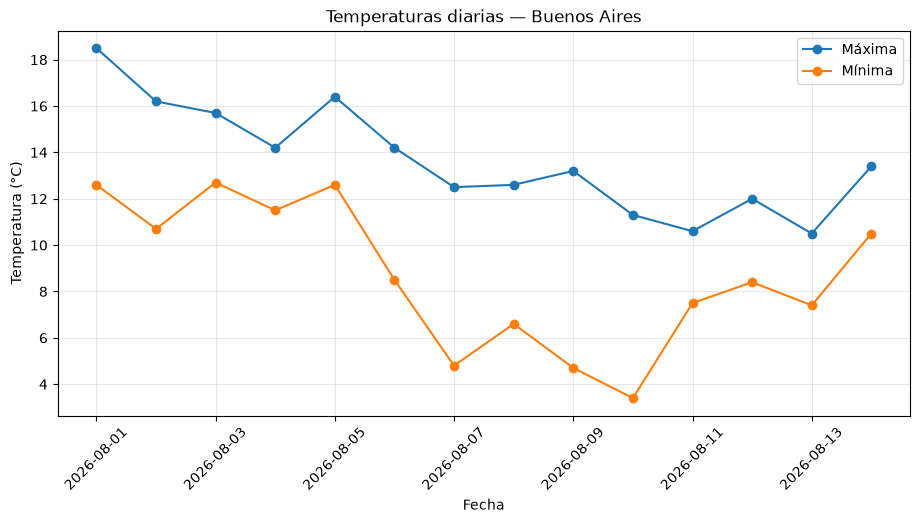

<Figure size 640x480 with 0 Axes>

In [4]:
# Creamos una figura con tamaño apropiado para mostrar varias fechas.
plt.figure(figsize=(11, 5))

# Graficamos la temperatura máxima y mínima en el mismo eje.
plt.plot(
    clima["fecha"],
    clima["temperatura_maxima"],
    marker="o",
    label="Máxima",
)
plt.plot(
    clima["fecha"],
    clima["temperatura_minima"],
    marker="o",
    label="Mínima",
)

# Agregamos título, etiquetas y leyenda para que el gráfico sea claro.
plt.title("Temperaturas diarias — Buenos Aires")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.show()
plt.tight_layout()

## 2. Gráfico de barras

Las barras permiten comparar la precipitación de cada día.

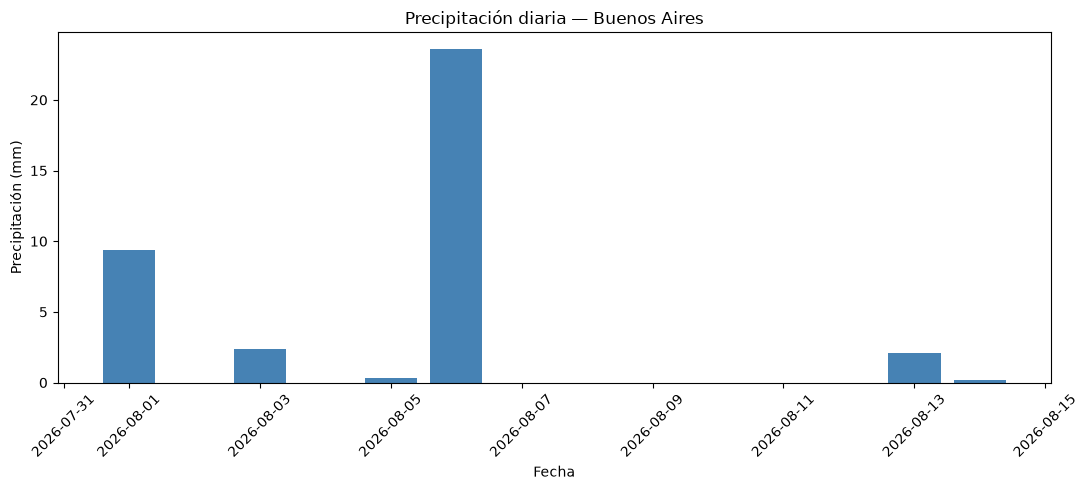

In [9]:
# Creamos un gráfico de barras para comparar la precipitación de cada día.
plt.figure(figsize=(11, 5))

plt.bar(
    clima["fecha"],
    clima["precipitacion"],
    color="steelblue",
)

# Agregamos título y nombres de eje para interpretar mejor el gráfico.
plt.title("Precipitación diaria — Buenos Aires")
plt.xlabel("Fecha")
plt.ylabel("Precipitación (mm)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 3. Destacar un valor

Podemos cambiar el color de las barras según una condición.

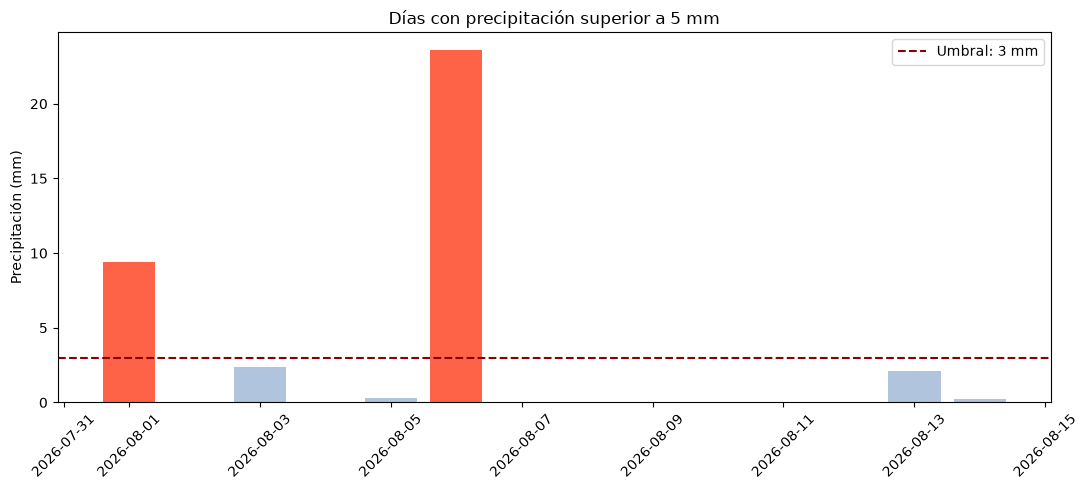

In [ ]:
# Definimos una lista de colores: los valores mayores a 5 mm se destacan en rojo.
colores: list[str] = [
    "tomato" if valor > 5 else "lightsteelblue"
    for valor in clima["precipitacion"]
]

plt.figure(figsize=(11, 5))
plt.bar(clima["fecha"], clima["precipitacion"], color=colores)
plt.axhline(5, color="darkred", linestyle="--", label="Umbral: 5 mm")

# El umbral ayuda a identificar fácilmente qué días tuvieron lluvia importante.
plt.title("Días con precipitación superior a 5 mm")
plt.ylabel("Precipitación (mm)")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4. Guardar el gráfico

`savefig()` exporta la figura. Debe ejecutarse antes de `show()`.

Gráfico guardado en: salidas\temperaturas.png


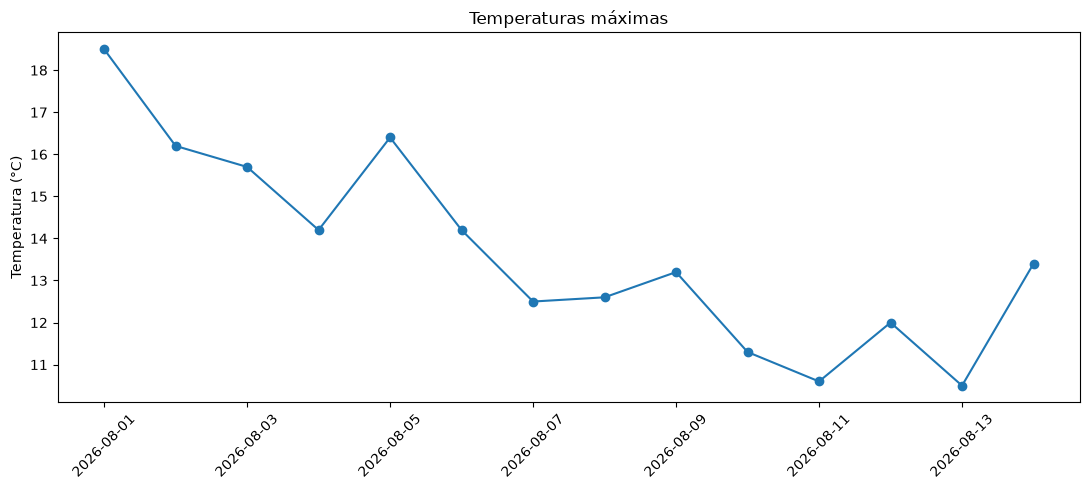

In [17]:
# Definimos la ruta del archivo PNG que queremos guardar en la carpeta salidas.
ruta_salida: Path = Path("salidas") / "temperaturas.png"
ruta_salida.parent.mkdir(exist_ok=True)

# Armamos un gráfico de temperaturas máximas diarias.
plt.figure(figsize=(11, 5))
plt.plot(clima["fecha"], clima["temperatura_maxima"], marker="o")
plt.title("Temperaturas máximas")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

# savefig() guarda la figura antes de mostrarla.

plt.savefig(ruta_salida, dpi=150)
print(f"Gráfico guardado en: {ruta_salida}")

plt.show()

# Ejercicio

Creá un gráfico de barras que represente la amplitud térmica diaria.

Requisitos:

1. Calcular `temperatura_maxima - temperatura_minima`.
2. Incluir título y nombres de ejes.
3. Rotar las fechas.
4. Destacar con otro color el día de mayor amplitud.
5. Guardar el gráfico como `salidas/amplitud_termica.png`.

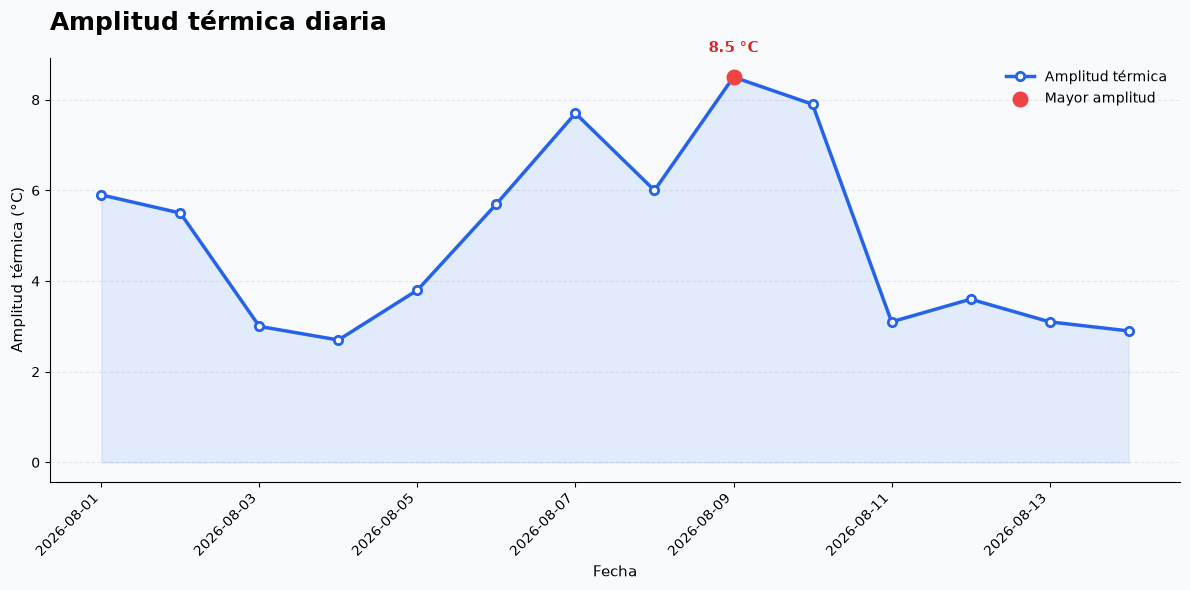

Gráfico guardado en: salidas\amplitud_termica.png


In [21]:

from pathlib import Path
import matplotlib.pyplot as plt

# Calculamos la amplitud térmica
clima["amplitud_termica"] = (
    clima["temperatura_maxima"] - clima["temperatura_minima"]
)

# Definimos dónde guardar el gráfico
ruta_salida = Path("salidas") / "amplitud_termica.png"
ruta_salida.parent.mkdir(parents=True, exist_ok=True)

# Creamos la figura y el área del gráfico
fig, ax = plt.subplots(figsize=(12, 6))

# Color de fondo
fig.patch.set_facecolor("#f8fafc")
ax.set_facecolor("#f8fafc")

# Dibujamos la línea principal
ax.plot(
    clima["fecha"],
    clima["amplitud_termica"],
    color="#2563eb",
    linewidth=2.5,
    marker="o",
    markersize=6,
    markerfacecolor="white",
    markeredgewidth=2,
    label="Amplitud térmica"
)

# Rellenamos el área bajo la curva
ax.fill_between(
    clima["fecha"],
    clima["amplitud_termica"],
    0,
    color="#3b82f6",
    alpha=0.12
)

# Identificamos el día con mayor amplitud
indice_max = clima["amplitud_termica"].idxmax()
dia_max = clima.loc[indice_max]

# Destacamos el valor máximo
ax.scatter(
    dia_max["fecha"],
    dia_max["amplitud_termica"],
    color="#ef4444",
    s=110,
    zorder=5,
    label="Mayor amplitud"
)

# Agregamos una anotación
ax.annotate(
    f'{dia_max["amplitud_termica"]:.1f} °C',
    xy=(dia_max["fecha"], dia_max["amplitud_termica"]),
    xytext=(0, 18),
    textcoords="offset points",
    ha="center",
    fontsize=11,
    fontweight="bold",
    color="#dc2626"
)

# Títulos y etiquetas
ax.set_title(
    "Amplitud térmica diaria",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Fecha", fontsize=11)
ax.set_ylabel("Amplitud térmica (°C)", fontsize=11)

# Cuadrícula horizontal suave
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Quitamos los bordes superiores y derechos
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Ajustamos las fechas
plt.xticks(rotation=45, ha="right")

# Agregamos leyenda
ax.legend(frameon=False)

# Ajustamos espacios
plt.tight_layout()

# Guardamos y mostramos
plt.savefig(ruta_salida, dpi=180, bbox_inches="tight")
plt.show()

print(f"Gráfico guardado en: {ruta_salida}")
